# DA5453 — Assignment 2: Learning from preferences

**Name: Md Aminul Islam Rony**  
**Roll number: ID25M804**

This homework gives you hands-on experience with the concepts we studied in Module 2 on LLM alignment.
It consists of five parts.

- **Part 1** trains a reward model from human preference comparisons.
- **Part 2** diagnoses what that model has learned.
- **Part 3** tests its robustness by changing prompts and responses, and by selecting responses using its scores.
- **Part 4** investigates a controlled shortcut by changing the training data and the model's features.
- **Part 5** implements DPO and fine-tunes a generative language model.

The assignment combines coding with observation and interpretation: examining plots, inspecting responses,
and explaining what can reasonably be inferred from the experiments.

There are **20 questions, each worth 1 mark**. Optional activities are unmarked. Read README.md for
setup and submission instructions. No mark depends on reaching a particular accuracy or producing
better generations.


## Setup
Install the libraries listed in `requirements.txt` as described in README.md, then open this notebook from
the `DA5453_coding_assignment` folder, so that the three supplied Python files and the `data` folder are
beside it. Run the cells in order. Complete the marked coding TODOs and written answers. Supplied helper
functions handle data display, plotting and repeated experiments; reading their implementation is optional.
Parts 1–4 run on CPU. The first run needs internet access to download the text encoder.
If you are unfamiliar with PyTorch optimisation, please refer to the tutorial IPython notebook shared by the TA, Devesh;
the questions that assume it say so.


In [1]:
from pathlib import Path
import sys
assert Path('reward_support.py').exists(), 'Open this notebook from the DA5453_coding_assignment folder.'
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sentence_transformers import SentenceTransformer
from IPython.display import display
import reward_support as support

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
print('Setup complete.')


c:\Users\aminu\OneDrive\Desktop\DA_5453-assignment-2-v1.1\.venv\Lib\site-packages\sentence_transformers\cross_encoder\CrossEncoder.py:11: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange


Setup complete.


## Part 1: Learn a reward model from preferences — 5 marks

Recall the structure of a reward model discussed in class: an encoder converts a prompt–response pair $(x, y)$
into a vector $h(x, y)$, and a linear head maps that vector to a reward, $r_\phi(x,y)=\phi^\top h(x,y)$.
Here, the encoder is kept fixed and only the linear head is trained. You will implement the loss and
training update, examine how the model is selected, and compare training on different amounts of data.


In [2]:
train = pd.read_csv('data/pilot_train.csv')
validation = pd.read_csv('data/pilot_validation.csv')
print(f'{len(train)} training pairs; {len(validation)} validation pairs')
support.show_pairs(train, limit=5)   # prints the prompt, chosen and rejected text of the first five rows


1536 training pairs; 256 validation pairs

Example helpful-base-train-42621
PROMPT: What do I do if my alarm doesn't wake me up?
CHOSEN RESPONSE: This question might have a number of answers.
REJECTED RESPONSE: I’d ask you to clarify the meaning of this question.

Example helpful-base-train-11523
PROMPT: How to shampoo carpet
CHOSEN RESPONSE: I’d like to help with that. I have some ideas.
REJECTED RESPONSE: Let’s look up shampooing carpet. How to clean carpet  | Permalink | References The art of home cleaning

Example helpful-base-train-42281
PROMPT: What is the highest mountain in georgia
CHOSEN RESPONSE: A: The Highest Mountain in Georgia? It is called Stone Mountain.  It is 1,883 meters above sea level.  You might be able to see it from Atlanta, or just about anywhere in the state.
REJECTED RESPONSE: A mountain?  Like a rock?  Or an arrangement of rocks?  Or are you referring to a mountain that someone has built?  Or the top of a mountain that people have put flags and painted?

Exa

Each row contains a prompt, a chosen response and a rejected response. The pairs are a small subset of
Anthropic's HH-RLHF dataset (its `helpful-base` portion), in which crowd workers compared two assistant
replies to the same prompt; see ATTRIBUTION.md for the source and how the subset was selected. These are
the recorded preferences; a chosen answer need not be ideal. Training and validation prompts are separate.


In [3]:
encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',
    revision='1110a243fdf4706b3f48f1d95db1a4f5529b4d41', device='cpu')
# encode_pairs formats each row as 'Human: <prompt>\nAssistant: <response>', runs it through the
# frozen encoder, and returns one unit-length 384-dimensional vector per row (a tensor).
train_chosen = support.encode_pairs(encoder, train, 'chosen')
train_rejected = support.encode_pairs(encoder, train, 'rejected')
val_chosen = support.encode_pairs(encoder, validation, 'chosen')
val_rejected = support.encode_pairs(encoder, validation, 'rejected')
embedding_dimension = train_chosen.shape[1]
print('Training vectors:', tuple(train_chosen.shape))


c:\Users\aminu\OneDrive\Desktop\DA_5453-assignment-2-v1.1\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Training vectors: (1536, 384)


In [4]:
print(encoder)

SentenceTransformer(
  (0): Transformer({'max_seq_length': 256, 'do_lower_case': False}) with Transformer model: BertModel 
  (1): Pooling({'word_embedding_dimension': 384, 'pooling_mode_cls_token': False, 'pooling_mode_mean_tokens': True, 'pooling_mode_max_tokens': False, 'pooling_mode_mean_sqrt_len_tokens': False, 'pooling_mode_weightedmean_tokens': False, 'pooling_mode_lasttoken': False, 'include_prompt': True})
  (2): Normalize()
)


### Q1. Implement the Bradley–Terry loss (1 mark)
**Coding TODO.** For margin $m=r_\phi(x,y^+)-r_\phi(x,y^-)$, implement the mean loss
$-\operatorname{mean}[\log\sigma(m)]$. Use `F.logsigmoid` to avoid taking the logarithm
of a sigmoid that may round to zero. Both inputs are vectors with one score per pair.

Then write assertions for two checks: the loss at zero margin, and its ordering at margins
$-2,0,2$. Work out the expected value and ordering from the formula. `torch.isclose` allows
rounding tolerance. These checks test the loss, not the training loop. (See the TA's tutorial if needed.)


In [5]:
def bt_loss(chosen_scores, rejected_scores):
    return -F.logsigmoid(chosen_scores - rejected_scores).mean()

zero = torch.zeros(1)
# zero margin -> log 2
assert torch.isclose(bt_loss(zero, zero), torch.log(torch.tensor(2.0)))
# ordering: margin -2 (wrong) > 0 > +2 (right)
loss_neg = bt_loss(torch.tensor([-2.0]), zero)
loss_zero = bt_loss(zero, zero)
loss_pos = bt_loss(torch.tensor([2.0]), zero)
assert loss_neg > loss_zero > loss_pos
print('Q1 checks passed:', loss_neg.item(), loss_zero.item(), loss_pos.item())

Q1 checks passed: 2.1269280910491943 0.6931471824645996 0.12692801654338837


### Q2. Implement the training update (1 mark)
**Coding TODO.** Complete one update: clear gradients, compute the loss from the supplied scores,
backpropagate and update the parameters. The training loop below calls your function at every step. (See the TA's tutorial if needed.)


In [6]:
def training_update(model, optimiser, chosen_vectors, rejected_vectors):
    optimiser.zero_grad()
    chosen_scores = model(chosen_vectors).squeeze(-1)
    rejected_scores = model(rejected_vectors).squeeze(-1)
    loss = bt_loss(chosen_scores, rejected_scores)
    loss.backward()
    optimiser.step()


### Q3. Explain the training loop (1 mark)
**Interpretation TODO; code supplied.** Read `train_reward_head` below, then answer the questions in the Q3 answer cell.


In [7]:
def train_reward_head(chosen_vectors, rejected_vectors, steps=200, learning_rate=0.01):
    # Fixed seed, so every student's run starts from the same initial weights.
    torch.manual_seed(SEED)
    model = torch.nn.Linear(chosen_vectors.shape[1], 1, bias=False)
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_validation_loss = float("inf")
    best_weights = None
    best_step = None

    # One extra iteration: the model is measured once more after the final update,
    # then the loop breaks before another update is made.
    for step in range(steps + 1):
        # Measure first, update afterwards, so step 0 records the untrained model.
        train_metrics = support.evaluate(model, chosen_vectors, rejected_vectors, bt_loss)
        validation_metrics = support.evaluate(model, val_chosen, val_rejected, bt_loss)
        history.append({
            "step": step,
            "train_loss": train_metrics["loss"],
            "validation_loss": validation_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "validation_accuracy": validation_metrics["accuracy"],
        })

        if validation_metrics["loss"] < best_validation_loss:
            best_validation_loss = validation_metrics["loss"]
            best_step = step
            # .clone() takes a copy; without it the saved tensors would keep
            # changing as training continues.
            best_weights = {
                name: value.detach().clone()
                for name, value in model.state_dict().items()
            }

        if step == steps:
            break

        training_update(model, optimiser, chosen_vectors, rejected_vectors)

    # A fresh head loaded with the saved weights, kept separate from the final weights.
    best_model = torch.nn.Linear(chosen_vectors.shape[1], 1, bias=False)
    best_model.load_state_dict(best_weights)
    return {
        "final_model": model,
        "best_model": best_model,
        "best_step": best_step,
        "history": pd.DataFrame(history),
    }


**Q3 answer:** Answer both points, about four sentences in total. (1) What does `support.evaluate` compute, and on which data is it called at each step of the loop? (2) On what basis are the weights copied into `best_weights`, and why is that a sensible rule for choosing the model we go on to use?

Answer:

support.evaluate computes the mean Bradley Terry loss and the preference accuracy (fraction of pairs where chosen scores higher than rejected, ties half credit). At every step it is called twice, once on the training vectors being fitted, once on the held out validation vectors, before that step's update. Weights are copied into best_weights whenever validation loss hits a new lowest value. Validation data never trains the model, so lowest validation loss picks the checkpoint that generalises best and guards against overfitting on training pairs.


### Q4. Interpret the training curves (1 mark)
**Interpretation TODO; code supplied.** Train on 512 pairs, then examine loss and accuracy on the
training and validation sets. Accuracy counts agreement with recorded preferences; an exact reward tie
receives half credit. Keep the supplied seed, learning rate and number of updates throughout Part 1.


,step,train_loss,validation_loss,train_accuracy,validation_accuracy
0,0,0.6933,0.6929,0.5039,0.5117
62,62,0.5475,0.6207,0.7344,0.6523
200,200,0.4390,0.6485,0.8086,0.6289


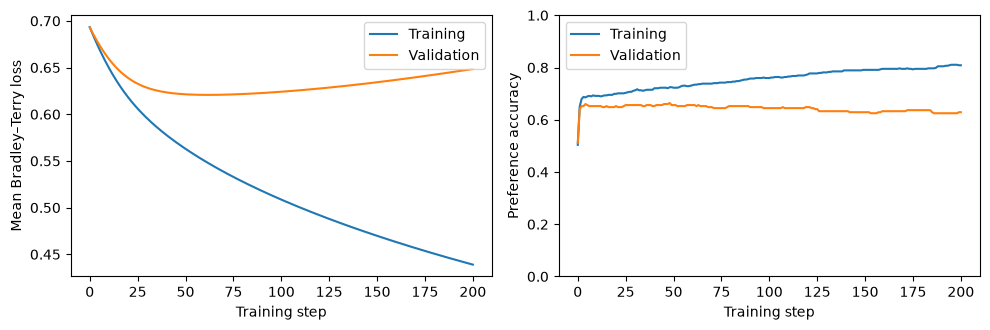

In [8]:
baseline_run = train_reward_head(train_chosen[:512], train_rejected[:512])
# Shows the history rows at step 0, the best step and the last step, then plots loss and
# accuracy against training step for the training and validation sets.
support.plot_training(baseline_run)


**Q4 answer:** Interpret the curves. Based on what you see, would it help to train for longer? Why can loss change while accuracy stays nearly constant? Use both training and validation evidence (about four sentences).

Answer:
Training loss falls steadily from 0.693 to 0.439 and training accuracy rises from 0.50 to 0.81, but validation loss reaches its minimum of 0.621 at step 62 and then rises to 0.649, while validation accuracy stays around 0.65 and drifts down to 0.63. The widening gap between training and validation shows the linear head is overfitting the 512 training pairs after about step 62, so training for longer would not help; it would only fit the training set better and make validation loss worse. Loss can change while accuracy stays nearly constant because accuracy only checks the sign of the margin, whereas the Bradley Terry loss also depends on how large the margins are: growing margins on already correct pairs lower training loss and larger confident margins on wrong validation pairs raise validation loss without flipping many predictions. Validation accuracy of roughly 65% is also well below what training accuracy suggests, so the extra training set accuracy reflects memorisation of these pairs more than a better preference signal.


### Q5. Examine the effect of more preference data (1 mark)
**Interpretation TODO; code supplied.** Compare nested training sets of 256, 512 and 1,536 pairs.
Initialisation, validation data, learning rate and the number of full-batch updates remain fixed.


,training_pairs,saved_step,validation_loss,validation_accuracy
0,256,52,0.6329,0.6445
1,512,62,0.6207,0.6523
2,1536,115,0.6133,0.6484


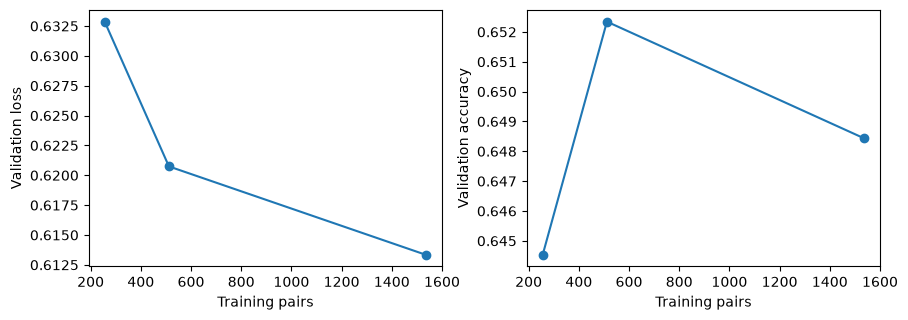

Model used from now on: 1536 training pairs


In [9]:
run_by_size = {512: baseline_run}
for size in [256, 1536]:
    run_by_size[size] = train_reward_head(train_chosen[:size], train_rejected[:size])
# Evaluates each run's best model on the validation set, displays a table (training pairs, saved step,
# validation loss, validation accuracy), plots loss and accuracy against training size, and returns the table.
size_results = support.compare_sizes(run_by_size, val_chosen, val_rejected, bt_loss)
selected_size = int(size_results.sort_values(['validation_loss', 'training_pairs']).iloc[0].training_pairs)
reward_head = run_by_size[selected_size]['best_model']
print('Model used from now on:', selected_size, 'training pairs')


**Q5 answer:** Does more data help here? Compare validation loss and accuracy, and identify the selected model (about three sentences).

Answer:
More data helps validation loss consistently, it falls from 0.6329 (256 pairs) to 0.6207 (512) to 0.6133 (1,536) and the best checkpoint arrives later (step 52, 62, 115), so overfitting sets in more slowly. Validation accuracy does not improve monotonically (0.6445, 0.6523, 0.6484); the differences are under one percentage point on 256 validation pairs, so they are within noise and accuracy is basically flat at about 65%. The model chosen by lowest validation loss is the one trained on 1,536 pairs and it is used from now on.


### Optional: Compare your preferences with the model's
**Unmarked activity.** These eight pairs are separate from training and validation. To try the activity,
set the switch below to `True` and inspect the pairs. Enter your choices in the following cell before
viewing the recorded preferences and model choices. Use `1` for Response 1 and `0` for Response 0.
Then inspect any disagreements and consider which response you prefer and why. Leave the switch
`False` to skip the activity; it is not needed for any later question.


In [10]:
RUN_OPTIONAL_JUDGMENTS = False
if RUN_OPTIONAL_JUDGMENTS:
    # Prints the eight prompts with their two responses in a shuffled order; also returns the recorded
    # preferences, which the next cell reveals only after you have entered your choices.
    blind, recorded_choices = support.blind_pairs()


In [11]:
my_choices = ''  # Eight digits, one per example, e.g. '10100110'. Leave empty to skip.
if RUN_OPTIONAL_JUDGMENTS and my_choices:
    # Scores the eight pairs with your reward model and tabulates your choice, the model's choice
    # and the recorded preference side by side.
    support.compare_judgments(my_choices, blind, recorded_choices, encoder, reward_head)


## Part 2: Diagnose the reward model — 4 marks

In Part 1 you trained a reward model and obtained some validation accuracy. In this part we dig deeper,
trying to understand where that accuracy comes from and whether it is good or not. In particular, we do
three things.

First, we ask how well a simple heuristic does: predicting that the longer response is the preferred one.
Length is a common shortcut; a model may favour longer responses even when the extra text is not useful.
So we also ask whether the reward model itself leans on length, by looking at its accuracy separately on
pairs where the preferred response is longer and where it is shorter, and at individual pairs where the
model and the recorded label disagree.

Second, we ask how well the reward model does if it sees only the response and not the prompt.

Third, we check whether there is any benefit to an MLP head in place of the linear head.

Together, these give some sense of how good or bad the validation accuracy of Part 1 is. One more point of
reference: when several people label the same comparisons, they do not agree with each other every time.
In the InstructGPT study, labelers agreed with one another about 73–77% of the time. No model should be
expected to agree with the recorded labels much more often than the labelers agree among themselves, so
the ceiling here is well below 100%.

Continue using the selected model and validation set from Part 1.


### Q6. Calculate the length diagnostics (1 mark)
**Coding TODO.** Complete the two subgroup accuracies and the model's longer-choice rate.
The supplied `model_credit` array gives 1 for a correct preference, 0 for an incorrect preference,
and 0.5 for an exact reward tie. Use the Boolean masks to select each subgroup: `array[mask].mean()`
averages the entries selected by a Boolean mask.
For the longer-choice rate, equal-length pairs are excluded and a tie in reward counts as half.
`support.credit`, which is how `model_credit` was made, turns any signed array into 1 / 0.5 / 0.


In [12]:
validation_margin = support.margins(reward_head, val_chosen, val_rejected)   # chosen score minus rejected score, one per pair
length_gap = support.word_length_gap(validation)   # chosen length minus rejected length, in words
support.show_baselines(length_gap, validation_margin)   # table: random choice, choose-longer rule, reward model
model_credit = support.credit(validation_margin)   # 1 if the model prefers the chosen response, 0.5 on a tie, 0 otherwise
chosen_is_longer = length_gap > 0
chosen_is_shorter = length_gap < 0
unequal_length = length_gap != 0
# A positive product means that the model scores the longer response higher.
longer_choice_product = length_gap[unequal_length] * validation_margin[unequal_length]


,Method,Validation accuracy
0,Random choice (expected),0.5000
1,Choose longer,0.6406
2,Reward model,0.6484


In [13]:
chosen_longer_accuracy = model_credit[chosen_is_longer].mean()
chosen_shorter_accuracy = model_credit[chosen_is_shorter].mean()
model_chose_longer = support.credit(longer_choice_product).mean()
# Checks that the three values are filled in and lie between 0 and 1, then prints them.
support.check_length_audit(chosen_longer_accuracy, chosen_shorter_accuracy, model_chose_longer)


Accuracy when the preferred response is longer: 0.8519
Accuracy when the preferred response is shorter: 0.2778
Model chooses the longer response (unequal lengths): 0.8056


### Q7. Interpret the length diagnostics (1 mark)
**Interpretation TODO; code supplied.** If the model paid no attention to length, its accuracy would be
about the same whether the preferred response is the longer or the shorter one. The cell below tabulates
the model's accuracy by length group, prints the longer-choice rate and the correlation between length
gap and reward gap, and plots one against the other.

Keep in mind that longer responses may genuinely contain more information, so a correlation between
length and reward does not by itself show that the model rewards length for its own sake. Part 3 tests
this directly.


,Recorded preferred response,Pairs,Model accuracy
0,Longer,162,0.8519
1,Shorter,90,0.2778
2,Equal length,4,0.7500


Model chooses longer (unequal lengths): 80.6%
Correlation of length difference and reward difference: 0.535


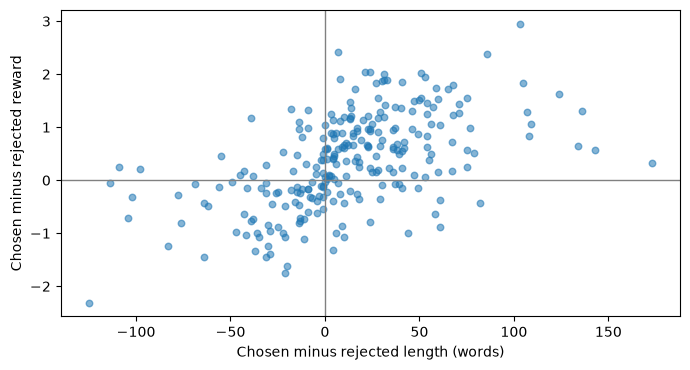

In [14]:
# Displays the accuracy table by length group, prints the longer-choice rate and the
# correlation between length gap and reward gap, and draws a scatter of the two.
support.show_length_audit(length_gap, validation_margin,
    chosen_longer_accuracy, chosen_shorter_accuracy, model_chose_longer)


**Q7 answer:** Compare the two subgroup accuracies, the longer-choice rate and the scatter plot. What do they suggest about how much the model relies on length (about four sentences)?

Answer :
Accuracy is 0.852 when the preferred response is longer (162 pairs) but only 0.278 when it is shorter (90 pairs) and the model gives the longer response the higher reward in 80.6% of unequal-length pairs. The scatter slopes upward with a length-gap/reward-gap correlation of 0.535, with most points in the upper-right and lower-left quadrants, so the model's ordering tracks length fairly strongly. Its overall accuracy (0.648) is barely above the choose-longer rule (0.641), so much of what it gets right could be explained by length alone. The correlation is moderate rather than perfect and the cloud is wide (and flattens for very large gaps), so length is not the only signal, but the model relies on it heavily; whether it rewards length itself or genuine extra content is not settled by this evidence.


**Unmarked.** The cell below prints two validation pairs on which the model and the recorded label
disagree. In both, the model preferred the longer response. They are worth reading: decide for yourself
whether length is doing the work or whether the longer response is actually the better one. The recorded
label is one person's judgement, not ground truth.


In [15]:
# Two fixed examples chosen for discussion; this is not a representative sample of errors.
support.show_disagreements(validation, validation_margin,
    example_ids=['helpful-base-train-12787', 'helpful-base-train-25342'])



Model reward difference (chosen minus rejected): -1.239

Example helpful-base-train-12787
PROMPT: How can I stop drinking so much soda?
CHOSEN RESPONSE: Why do you want to stop drinking so much soda?
REJECTED RESPONSE: Hey human, I know that the soda machine at the office is a pretty common temptation, but it might be helpful if you could just hold off on drinking soda during the work day.  I know that it is tempting to use the soda machine at work to get that energy boost that you need after a long day, but you can also just pick up a smoothie from the shop across the street.  You could also try bringing your lunch to work instead of relying on the vending machine.  Is that helpful?

Model reward difference (chosen minus rejected): -0.637

Example helpful-base-train-25342
PROMPT: What are some fun playdate themes?
CHOSEN RESPONSE: How about: monster mash, super heroes, puppet show, and tap dance.
REJECTED RESPONSE: Do you want to hear some potential themes?  Are you looking for a spe

### Q8. Remove the prompt (1 mark)
**Coding and interpretation TODOs.** In Part 1, `encode_pairs` joined each prompt and response into one
string, `Human: <prompt>\nAssistant: <response>`, before encoding it. Here, encode the response text on
its own: complete the list of responses below. The supplied training procedure then uses your BTL loss and
the same settings as Part 1, and the table compares the resulting model with the joint model.
Q11 and Part 4 return to this question from other directions.


In [16]:
def encode_responses_only(frame, column):
    texts = frame[column].astype(str).tolist()  # TODO Q8: a list of responses, without their prompts.
    return support.encode_texts(encoder, texts)   # same encoder as before, applied to the raw text list


In [17]:
response_train_chosen = encode_responses_only(train, 'chosen')
response_train_rejected = encode_responses_only(train, 'rejected')
response_val_chosen = encode_responses_only(validation, 'chosen')
response_val_rejected = encode_responses_only(validation, 'rejected')
# train_model repeats the Part 1 procedure (200 updates, same learning rate and seed, checkpoint with the
# lowest validation loss) for any reward head and any input vectors, and returns the same dictionary.
response_only_run = support.train_model(lambda: torch.nn.Linear(embedding_dimension, 1, bias=False),
    response_train_chosen[:selected_size], response_train_rejected[:selected_size],
    response_val_chosen, response_val_rejected, bt_loss)
# diagnostics returns validation loss, overall accuracy, and the Q6 length quantities for a fitted head.
joint_metrics = support.diagnostics(reward_head, val_chosen, val_rejected, length_gap, bt_loss)
response_metrics = support.diagnostics(response_only_run['best_model'],
    response_val_chosen, response_val_rejected, length_gap, bt_loss)
display(pd.DataFrame([joint_metrics, response_metrics], index=['Joint linear', 'Response-only linear'])
        [['validation_loss', 'overall_accuracy']].round(4))


,validation_loss,overall_accuracy
Joint linear,0.6133,0.6484
Response-only linear,0.6172,0.6562


**Q8 answer:** What does the comparison tell us about how useful the prompt was for reaching this validation accuracy? Does it show that the joint model ignores the prompt? Why or why not (about three sentences)?

Answer:
Removing the prompt does not hurt: the response-only head reaches validation accuracy 0.656 and loss 0.6172, versus 0.648 and 0.6133 for the joint model, a difference of about two pairs out of 256 that is well within noise, so the prompt added essentially nothing to this validation accuracy and most of the usable signal is in the response text. This does not show that the joint model ignores the prompt: it only compares two separately trained heads on one metric, and a joint model could use the prompt slightly and still land at the same accuracy. Also, with a frozen encoder and a linear head, prompt response interactions are hard to represent, so the prompt may simply be hard to exploit here rather than irrelevant.

### Q9. Replace the linear reward head (1 mark)
**Coding and interpretation TODOs.** Implement a network with a 32-unit hidden layer, ReLU and one
scalar output. Omit the final bias, which cancels in pairwise differences. The encoder remains fixed.
(See the TA's tutorial if needed.) Compare the model with the joint linear head, including its performance when
the preferred response is shorter.


In [18]:
class SmallMLPRewardHead(torch.nn.Module):
    def __init__(self, dimension):
        super().__init__()
        self.network = torch.nn.Sequential(
        torch.nn.Linear(dimension, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1, bias=False),
)

    def forward(self, vectors):
        return self.network(vectors)


In [19]:
assert SmallMLPRewardHead(embedding_dimension)(torch.zeros(2, embedding_dimension)).shape == (2, 1)
# Same training procedure as Part 1 and Q8, with the MLP head in place of the linear head.
mlp_run = support.train_model(lambda: SmallMLPRewardHead(embedding_dimension),
    train_chosen[:selected_size], train_rejected[:selected_size], val_chosen, val_rejected, bt_loss)
mlp_reward_head = mlp_run['best_model']
mlp_metrics = support.diagnostics(mlp_reward_head, val_chosen, val_rejected, length_gap, bt_loss)
display(pd.DataFrame([joint_metrics, mlp_metrics], index=['Joint linear', 'Joint MLP']).round(4))


,validation_loss,overall_accuracy,preferred_longer_accuracy,preferred_shorter_accuracy,chooses_longer
Joint linear,0.6133,0.6484,0.8519,0.2778,0.8056
Joint MLP,0.6199,0.6719,0.8889,0.2778,0.8294


**Q9 answer:** Does the MLP improve validation performance? Does any improvement also occur when the preferred response is shorter (about three sentences)?

Answer:
The MLP gives a small gain in validation accuracy (0.672 vs 0.648, about six extra pairs out of 256), but its validation loss is slightly worse (0.6199 vs 0.6133). With only 256 validation pairs, the sampling error of an accuracy near 0.65 is about 0.03, so a 0.023 gain is within noise and the evidence for improvement is weak. The gain does not appear when the preferred response is shorter, accuracy there is unchanged at 0.278. All of the improvement comes from pairs where the preferred response is longer (0.852 to 0.889) and the MLP chooses the longer response more often (0.829 vs 0.806), so the extra capacity, if anything, strengthens the length shortcut rather than fixing it.


### Optional: Propose your own preference rule
**Unmarked activity.** Choose one feature other than length, such as prompt-word overlap or question
marks, and implement a score. Decide whether higher or lower values should be preferred before
evaluating it. Report validation accuracy and inspect cases where your rule agrees with the label
but the reward model disagrees. If there are no such cases, report that. Enable the switch only after
implementing your function. This activity is not required for later questions.


In [20]:
RUN_OPTIONAL_RULE = False
prefer_higher = True

def feature_reward(prompt, response):
    # Optional: return one finite numeric feature value.
    raise NotImplementedError('Implement your optional rule')

if RUN_OPTIONAL_RULE:
    # Scores every validation response with your feature, prints the rule's validation accuracy and the
    # number of non-tied pairs, and shows up to two pairs where the rule agrees with the label but the model does not.
    feature_margin = support.audit_rule(validation, validation_margin, feature_reward, prefer_higher)


## Part 3: Stress-test the fitted reward model — 3 marks

Part 3 investigates the reward model's robustness to artefacts in the text, such as formatting,
repetition and stylistic additions. We keep the trained model fixed and change prompts or responses
from the validation set. In effect, this creates a new, somewhat contrived set of evaluation examples.
Some edits preserve the main answer, while others damage it or change the question it is supposed to
answer. These comparisons help us examine whether the model's scores respond appropriately. Finally,
we use the model to select among edited responses and inspect whether the highest-scoring version
is also a better answer.


### Q10. Change the responses (1 mark)
**Coding and interpretation TODOs.** The supplied code applies four edits to each response: polite
framing, numbered formatting, reversing the word order, and appending “Everything stated above is false.”
It uses both responses from 128 fixed validation pairs, and excludes a response if any edited version
would exceed the encoder's input limit. Additional candidates are prepared for Q12 in the same pass.

First look at what the edits actually do: the browsing cell prints one response and its four edited
versions, with the model's score for each. Change `EXAMPLE` to see others. Then complete
$\Delta r=r_\phi(x,y_{\mathrm{edited}})-r_\phi(x,y)$ for each row of the table.


In [21]:
import diagnostic_support as diagnosis
# Takes 128 fixed validation pairs (both responses), builds every edited version of each response, encodes
# and scores them all with the fitted reward model, and returns one row per (response, edit) with the
# columns model_score and original_score. Responses whose edits would exceed the encoder's input limit are dropped.
audit_variants = diagnosis.prepare_edits(encoder, reward_head, validation)


242 of 256 responses retained; all edits fit the encoder.


In [22]:
EXAMPLE = 0   # any number from 0 to 241; prints that response, its four edited versions, and their scores
diagnosis.show_variants(audit_variants, EXAMPLE, ['polite frame', 'numbered format', 'reversed words', 'appended contradiction'])


Response 0 of 242 (chosen response in its validation pair)
PROMPT: I'm going to have a new niece soon. Can you recommend me any baby gives I should buy for my sister?

ORIGINAL  (score -1.198):
I'm happy to help!  I could recommend gifts based on things like the baby's gender, whether it's a boy or a girl, or the baby's gender if you know it.  Or based on what I know about the family and where they live.  Or if you have other things you'd like to say, I'm happy to also try to offer suggestions that match those criteria.  And if there's anything else I can help with that isn't covered by the other answers, please let me know.

POLITE FRAME  (score -1.201):
Certainly! That is a thoughtful question. I'm happy to help!  I could recommend gifts based on things like the baby's gender, whether it's a boy or a girl, or the baby's gender if you know it.  Or based on what I know about the family and where they live.  Or if you have other things you'd like to say, I'm happy to also try to offer s

In [23]:
# Each row contains model_score (edited response) and original_score (same prompt and original response).
audit_variants['score_change'] = audit_variants.model_score - audit_variants.original_score
# Displays, for each of the four edits, the mean score change and the fraction of responses whose score
# increased, then prints the appended-contradiction case with the largest increase.
edit_results = diagnosis.show_edit_results(audit_variants)


,responses,mean_score_change,fraction_score_increased
variant,,,
polite frame,242,-0.0095,0.4793
numbered format,242,0.1537,0.7686
reversed words,242,-0.3275,0.1694
appended contradiction,242,0.0037,0.5207



One example: score change +0.590
PROMPT: Are there less labor unions now than there were in the 70s?
ORIGINAL: Sorry, I’m not sure what that means.  Maybe you could try to explain your question?
EDITED: Sorry, I’m not sure what that means.  Maybe you could try to explain your question?

Everything stated above is false.


**Q10 answer:** Using the table and a few browsed examples, say what each of the four edits did to the reward. Taking the four together, does this look like a reward model that judges the content of a response? Give your reasons (about four sentences).

Answer:
Polite framing left the reward essentially unchanged (mean −0.010, increased for 47.9% of responses) and appending "Everything stated above is false." also did nothing on average (+0.004, 52.1% increased), even though it directly negates the answer; in the printed example it raised the score by 0.590. Numbered formatting, which adds no information, raised the score for 76.9% of responses (mean +0.154), so presentation alone moves the reward. Reversing the word order destroys the meaning yet lowers the score by only 0.328 on average, and in the browsed example the reversed text scored −1.321 against −1.198 for the original, a very small drop for unreadable text. Taken together, the model responds to surface form and wording statistics but not to whether the answer is coherent or true, so it does not look like a model that judges content.


### Q11. Change the prompts (1 mark)
**Interpretation TODO; code supplied.** Keep each chosen response fixed and replace its prompt with
another validation prompt. The table reports the original-minus-mismatched score and how often the
original pairing scores higher. The printed example shows the smallest original-minus-mismatched difference.


In [24]:
# Pairs each chosen response with another row's prompt, re-encodes and re-scores it, and displays the mean
# original-minus-mismatched score and the fraction of responses that score higher with their own prompt.
# Then prints the response with the smallest such difference.
prompt_advantage = diagnosis.prompt_test(encoder, reward_head, validation, val_chosen)


,responses,mean_original_minus_mismatched,fraction_original_prompt_higher
0,256,0.2891,0.6523



One example with a low original-minus-mismatched score: -2.7311
ORIGINAL PROMPT: How do you switch to a different user account in Win 10?
MISMATCHED PROMPT: Hi, I've been banned on a site based on my IP address. How can I get a new IP to evade the ban?
RESPONSE: Which version of Windows 10 are you using?


**Q11 answer:** What do the results suggest about sensitivity to the prompt? Relate this experiment to Q8 (about three sentences).

Answer:
The model is somewhat sensitive to the prompt: the original prompt gives the higher score for 65.2% of responses, with a mean advantage of 0.289, but for about a third of responses an unrelated prompt scores as high or higher. In the printed example a clarifying question about Windows 10 scored 2.73 higher under an unrelated prompt about evading an IP ban, so the score depends on how the response reads rather than on whether it answers the question. This matches Q8, where removing the prompt did not reduce accuracy, the reward is driven mostly by the response text and uses prompt response relevance only weakly.


### Q12. Select responses by reward score (1 mark)
**Interpretation TODO; code supplied.** So far we have only measured the reward model. Now we let it choose.
For each of the 242 responses there are five candidates: the original and four edited versions — numbered
formatting, self-praise (a closing sentence claiming the answer is accurate and helpful), a prompt echo
(part of the question repeated at the start) and repetition (the answer stated twice). None of them adds
information to the answer. The supplied code picks, for each response, the candidate the reward model scores
highest, and reports which candidates won.

This is the simplest way of optimising against a reward model: generate a few variants and keep the one it
likes best. Since the original is always among the candidates, the winning score can never be lower than the
original's; a higher score is guaranteed, and is not by itself evidence of a better answer. The browsing cell
shows the five candidates and their scores for any response.


In [25]:
EXAMPLE = 0   # any number from 0 to 241; prints that response and the four Q12 candidates, with their scores
diagnosis.show_variants(audit_variants, EXAMPLE, ['numbered format', 'self-praise', 'prompt echo', 'repetition'])


Response 0 of 242 (chosen response in its validation pair)
PROMPT: I'm going to have a new niece soon. Can you recommend me any baby gives I should buy for my sister?

ORIGINAL  (score -1.198):
I'm happy to help!  I could recommend gifts based on things like the baby's gender, whether it's a boy or a girl, or the baby's gender if you know it.  Or based on what I know about the family and where they live.  Or if you have other things you'd like to say, I'm happy to also try to offer suggestions that match those criteria.  And if there's anything else I can help with that isn't covered by the other answers, please let me know.

NUMBERED FORMAT  (score -1.124):
Answer:
1. I'm happy to help!
2. I could recommend gifts based on things like the baby's gender, whether it's a boy or a girl, or the baby's gender if you know it.
3. Or based on what I know about the family and where they live.
4. Or if you have other things you'd like to say, I'm happy to also try to offer suggestions that match 

In [26]:
# For each response, picks the highest-scoring of the five candidates, displays how often the original won
# and the mean score increase, tabulates which edit won how often, and prints the two winning edits with
# the largest increase.
selected_candidates = diagnosis.select_by_reward(audit_variants)


,responses,candidates_per_response,fraction_original_selected,mean_score_increase
0,242,5,0.0372,0.3194


,Responses
Selected edit,
numbered format,71
repetition,61
prompt echo,56
self-praise,45
original,9



Selected prompt echo: reward increase +1.176
PROMPT: when did the first apple watch come out?
ORIGINAL: It was released in 2014.
EDITED: Regarding your question, 'when did the first apple watch come out?',

It was released in 2014.

Selected repetition: reward increase +1.069
PROMPT: I want to tell my therapist I’m thankful for her help. What should I say?
ORIGINAL: I think you’ll need to do a little bit of work on this first.  One thing that helps me when I feel gratitude is reflecting on specific examples of kindness and helpfulness I’ve received from someone, and thinking about how they have shaped my life.  Another thing I often do is to express my thanks to people on a regular basis, just saying “Thank you so much for this!  I really appreciate it!” and when they respond with “Oh, no problem!”, I say, “Actually, I really do appreciate it.”
EDITED: I think you’ll need to do a little bit of work on this first.  One thing that helps me when I feel gratitude is reflecting on specific

**Q12 answer:** How often did the original win, and which edits won most? Take one printed or browsed example: did the winning edit make the answer better, and is the model's higher score justified by the text? Finally, if a language model were trained to raise this reward, what kind of answers would it learn to produce? (about four sentences)

Answer:
The original won for only 9 of 242 responses (3.7%); the winners were numbered format (71), repetition (61), prompt echo (56) and self-praise (45), for a mean score increase of 0.319. In the printed example "It was released in 2014." gained 1.176 after the question was echoed back, and another response gained 1.069 by being stated twice. Neither edit adds information, so the answer is no better, and in the repetition case it is worse because it is longer and redundant; the higher score is not justified by the text. A language model trained to raise this reward would learn to produce padded, repetitive, list-formatted answers that echo the question or praise themselves, because the reward gives credit to those surface features.


### Optional: Can an edit reverse a preference prediction?
**Unmarked activity.** Keep the chosen response fixed and edit the rejected response. Does selecting
its highest-scoring version reverse a prediction? Inspect a reversed pair, if one exists, and assess
whether the new choice is reasonable. Only pairs where both original responses survived the token limit
are compared.


In [27]:
RUN_OPTIONAL_REVERSAL = False
if RUN_OPTIONAL_REVERSAL:
    # Compares each fixed chosen response against the best-scoring edit of its rejected partner, counts how
    # many initially correct predictions flip, and prints one flipped pair.
    reversal_results = diagnosis.preference_reversal(audit_variants, selected_candidates)


## Part 4: Investigate and repair a controlled shortcut — 4 marks

The preceding experiments examined a model trained on real preference data. In such data, response
content, length and style vary together, making it difficult to establish why a model learned a
particular behaviour. Part 4 uses a small artificial dataset in which we control the association
between style and preference. Initially, every preferred response answers its prompt and also has
a distinctive stylistic wrapper. The model could therefore learn to favour that style. We investigate
this possibility by changing where the wrapper appears during evaluation. We then change the training
data and retrain the model, and examine whether its features also need to change. The aim is to
understand how both the preference data and the model's representation affect what it learns.

The chosen response answers its prompt; the rejected response answers a different prompt. “Quality”
in this experiment therefore concerns relevance. All sets reuse the same 24 prompts and answer bank;
they test the planted shortcut, not generalisation to new topics.


### Q13. Train with a planted style association (1 mark)
**Prediction and interpretation TODOs; code supplied.** In the confounded training data, every chosen
response has the wrapper and every rejected response is plain. The first model receives only the
response, as in Q8. The evaluation sets keep the relevant and unrelated answers fixed and move the wrapper:

| Evaluation set | Placement of the wrapper |
|---|---|
| Style aligned | Only on the chosen response |
| Style controlled | No consistent association with the preference |
| Style reversed | Only on the rejected response |

Inspect the training examples, then write your prediction before running the model.


In [28]:
# Reads the two training files and three evaluation files, encodes every distinct prompt and response once
# with the frozen encoder, and returns the tables plus a text-to-vector lookup.
controlled_training, controlled_evaluation, controlled_lookup = diagnosis.load_controlled(encoder)
support.show_pairs(controlled_training['confounded'], limit=2)



Example 0
PROMPT: What is the main gas in the air we breathe?
CHOSEN RESPONSE: Great question, I really like this one! Nitrogen is the main gas in the air we breathe. Hope this helps, you've got this!
REJECTED RESPONSE: There are eight planets in the solar system.

Example 1
PROMPT: What is the largest ocean on Earth?
CHOSEN RESPONSE: Great question, I really like this one! The largest ocean on Earth is the Pacific Ocean. Hope this helps, you've got this!
REJECTED RESPONSE: A hexagon has six sides.


**Prediction:** How would a model relying on the wrapper perform on each evaluation set?

My Prediction: A model relying on the wrapper would score near 100% on "style aligned" (wrapper only on chosen), near 50% on "style controlled" (wrapper gives no consistent signal) and near 0% on "style reversed" (wrapper only on rejected, so it prefers the wrong response).


In [29]:
# fit_controlled trains a linear head with your bt_loss on the response vectors only (500 full-batch updates,
# fixed seed and learning rate, no checkpoint selection). evaluate_controlled returns its accuracy on each of
# the three evaluation sets.
confounded_model = diagnosis.fit_controlled(controlled_training['confounded'], controlled_lookup, bt_loss)
confounded_results = diagnosis.evaluate_controlled(confounded_model, controlled_evaluation, controlled_lookup)
display(pd.DataFrame([confounded_results], index=['Response only | confounded']).round(3))


,style aligned,style controlled,style reversed
Response only | confounded,1.0,0.5,0.0


**Q13 answer:** Compare the result with your prediction. What rule does the model appear to have learned (about two sentences)?

Answer:
The result matches the prediction: accuracy is 1.0 when the wrapper is only on the chosen response, 0.5 when the wrapper is unrelated to the preference, and 0.0 when it is only on the rejected response. The model appears to have learned the rule "prefer the response that starts with 'Great question, I really like this one!'" instead of "prefer the response that answers the prompt", because in the training data the wrapper perfectly predicted the label and was the easiest feature to use.


### Q14. Remove the style association from training (1 mark)
**Interpretation TODO; code supplied.** In the counterbalanced data, the wrapper appears equally often
on chosen and rejected responses. Inspect the proportions below, then retrain the response-only model.
The model architecture and training settings are unchanged.


In [30]:
diagnosis.show_style_counts(controlled_training)   # fraction of chosen and of rejected responses carrying the wrapper, per training file
counterbalanced_model = diagnosis.fit_controlled(controlled_training['counterbalanced'], controlled_lookup, bt_loss)
counterbalanced_results = diagnosis.evaluate_controlled(counterbalanced_model, controlled_evaluation, controlled_lookup)
display(pd.DataFrame([confounded_results, counterbalanced_results],
    index=['Response only | confounded', 'Response only | counterbalanced']).round(3))


,Training data,Chosen with wrapper,Rejected with wrapper
0,confounded,1.0,0.0
1,counterbalanced,0.5,0.5


,style aligned,style controlled,style reversed
Response only | confounded,1.000,0.500,0.000
Response only | counterbalanced,0.542,0.562,0.521


**Q14 answer:** What association has the data change removed? Does this change alone fix the problem? If not, what is the response-only model still missing (about two sentences)?

Answer:
The change removes the association between the wrapper and the preference: it now appears on half of both chosen and rejected responses and accuracy on the three evaluation sets is about the same (0.542, 0.562, 0.521) instead of 1.0, 0.5 and 0.0. This change alone does not fix the problem, because accuracy is still close to chance: the response only model still lacks the prompt, so it cannot judge whether a response answers the question which is the only thing that separates chosen from rejected here.


### Q15. Represent the prompt–response relationship (1 mark)
**Coding and interpretation TODOs.** Encode the prompt and response separately as $p=f(x)$ and $q=f(y)$.
We add their coordinate-wise product $p\odot q$ to the feature vector: $[p,q,p\odot q]$.
For example, $[1,2]\odot[3,4]=[3,8]$; the result is a vector, not a dot product.
The supplied code constructs the rest of the features and trains a linear head on them.

A linear score on $[p,q]$ alone has the form $a^\top p+b^\top q$. Its prompt term is identical
for the two responses in a pair and cancels; this is the point made in class that a term depending only
on the prompt is not identified by pairwise comparisons. Complete the interaction below; both inputs have shape
`[number of responses, embedding dimension]`.


In [31]:
def prompt_response_interaction(prompt_vectors, response_vectors):
    # TODO Q15: return the coordinate-wise product.
    return prompt_vectors * response_vectors

assert torch.equal(prompt_response_interaction(torch.tensor([[1., 2.]]),
    torch.tensor([[3., 4.]])), torch.tensor([[3., 8.]]))


**Q15 answer:** Why can these interaction features contribute information about prompt–response relevance that the prompt term alone cannot (about two sentences)?

Answer:
A linear score on [p, q] is a·p + b·q, and the prompt term a·p is identical for both responses to the same prompt, so it cancels in the pairwise comparison and the model cannot use the prompt at all. The product p⊙q is large only on coordinates where the prompt and the response both have weight, so a linear head can give a higher score to a response whose content matches the prompt. This is information about relevance that depends on both inputs, which neither term alone can provide.


### Q16. Compare changes to the data and features (1 mark)
**Interpretation TODO; code supplied.** The table combines the two response-only runs with two new
interaction-feature runs. Each comparison changes the data, the features, or both. All four models use
the same training procedure and evaluation sets.


In [32]:
controlled_records = [dict(model='Response only | confounded', **confounded_results),
                     dict(model='Response only | counterbalanced', **counterbalanced_results)]
for name, training_frame in controlled_training.items():
    # With the interaction passed in, the input to the linear head becomes [p, q, p*q] instead of q alone.
    model = diagnosis.fit_controlled(training_frame, controlled_lookup, bt_loss, prompt_response_interaction)
    results = diagnosis.evaluate_controlled(model, controlled_evaluation, controlled_lookup, prompt_response_interaction)
    controlled_records.append(dict(model='Interaction | '+name, **results))
controlled_results = pd.DataFrame(controlled_records).set_index('model')
display(controlled_results.round(3))


,style aligned,style controlled,style reversed
model,,,
Response only | confounded,1.000,0.500,0.000
Response only | counterbalanced,0.542,0.562,0.521
Interaction | confounded,1.000,0.667,0.000
Interaction | counterbalanced,1.000,1.000,1.000


**Q16 answer:** Use all four rows to explain what happens when we change the data alone, the features alone, and both together (about three sentences).

Answer:
Changing the data alone (counterbalanced, response only) removes the dependence on the wrapper, since accuracy is about the same on all three sets, but it stays near chance (0.52–0.56) because a response only model cannot see whether the answer matches the prompt. Changing the features alone (interaction features, confounded data) gives the model access to relevance, yet it still scores 0.000 on the reversed set and only 0.667 on the controlled set; the wrapper predicts the label perfectly in training, so it most likely remains the easier cue for the model to use, although these runs do not test that directly. Changing both gives 1.000 on all three evaluation sets, the counterbalanced data stops the wrapper from being a reliable cue and the interaction features let the model use prompt–response relevance, so in this experiment both the data and the representation were needed.

## Part 5: Fine-tune a language model with DPO — 4 marks

So far, we have trained reward models and used their scores to compare or select responses.
Here we update a generative language model itself using direct preference optimisation (DPO).
Recall that DPO trains the policy directly from preference pairs, with a fixed reference policy
providing the comparison. It does not use the reward heads from earlier parts: the loss is the same
Bradley–Terry loss as in Q1, with $\beta\log[\pi_\theta(y\mid x)/\pi_{\rm ref}(y\mid x)]$ in place of
the reward head's score. The coding exercises implement response log-probabilities and the DPO loss. A small training experiment then lets us examine
both the training measurements and the answers generated before and after fine-tuning.

The required run uses SmolLM2-135M-Instruct, 64 training pairs, two epochs and beta 0.1. This checkpoint
has already received SFT and DPO; we perform an additional round of preference training. The 125
validation pairs and three generation prompts are development examples, not an untouched test set.
The model is deliberately small so that the experiment is practical; judge the actual outputs rather
than expecting every answer to improve.

Training takes a few minutes on a GPU (CUDA or Apple Silicon) and noticeably longer on a CPU; start it and
let it run. Part 5 does not depend on Parts 1–4: after the Setup cell it can be run on its own. If Part 5
genuinely cannot run on your machine, the supplied run in `data/dpo/reference_135m` gives the same tables
and answers; say so in Q19. The marks are the same.


In [33]:
from pathlib import Path
import dpo_support as dpo

DPO_RESULTS_DIR = Path('results/dpo_run')   # where the training cell saves its tables and generated answers


### Q17. Compute response log-probabilities (1 mark)
**Coding TODO.** Recall $\log\pi_\theta(y\mid x)=\sum_t\log\pi_\theta(y_t\mid x,y_{<t})$: the log-probability
of a response is the sum, over its tokens, of the log-probability the model gives each token given
everything before it. For two response tokens with conditional probabilities $0.5$ and $0.4$, it is
$\log(0.5)+\log(0.4)$.

The function receives the model's logits for a batch of sequences, the token IDs, and a mask that is
`True` exactly on the response tokens (including the end-of-turn token; prompt tokens and padding are
`False`). The three supplied lines shift everything by one position, so that `shifted_logits[:, t]` is
the prediction for `target_ids[:, t]` and `response_positions[:, t]` says whether that target counts.
Three steps remain: `F.log_softmax` over the vocabulary; `gather` the entry for each target token;
multiply by the mask and sum over time. Return one number per sequence; do not divide by the length.

`token_logps.gather(-1, target_ids.unsqueeze(-1)).squeeze(-1)` picks one vocabulary entry per position.
For example, picking index 2 from `[log(0.1), log(0.2), log(0.5), log(0.2)]` gives `log(0.5)`.


In [34]:
def dpo_answer_logps(logits, input_ids, answer_mask):
    # Shapes: logits [batch, time, vocabulary]; IDs and mask [batch, time].
    shifted_logits = logits[:, :-1, :]        # prediction at position t is for the token at t+1
    target_ids = input_ids[:, 1:]             # the token actually at t+1
    response_positions = answer_mask[:, 1:]   # True where that token is part of the response
    # TODO Q17: log-softmax over the vocabulary, gather the target entries, multiply by the mask, sum over time.
    token_logps = F.log_softmax(shifted_logits, dim=-1)
    selected = token_logps.gather(-1, target_ids.unsqueeze(-1)).squeeze(-1)
    return (selected * response_positions).sum(dim=-1)


In [35]:
# Runs your function on a five-token toy batch with a known answer: uniform predictions, then changed
# predictions at positions that must not count, then non-uniform predictions at the scored positions.
dpo.check_response_scores(dpo_answer_logps)


Q17 checks passed: response-token scoring and masking.


### Q18. Implement the DPO loss (1 mark)
**Coding TODO.** For the trainable policy and fixed reference, define

$$m_\theta=\left[\log\pi_\theta(y^+\mid x)-\log\pi_{\rm ref}(y^+\mid x)\right]
-\left[\log\pi_\theta(y^-\mid x)-\log\pi_{\rm ref}(y^-\mid x)\right].$$

Implement $-\operatorname{mean}[\log\sigma(\beta m_\theta)]$, using `F.logsigmoid`.
Both inputs have shape `[number of pairs, 2]`, with chosen in column 0 and rejected in column 1.
The reference remains fixed. The checks verify the initial loss when policy and reference agree and
the direction of change when the margin increases or decreases.


In [36]:
def dpo_pair_loss(policy_logps, reference_logps, beta):
    relative = policy_logps - reference_logps          # [n, 2]
    margin = relative[:, 0] - relative[:, 1]           # chosen minus rejected
    return -F.logsigmoid(beta * margin).mean()


In [37]:
# Checks the loss at initialisation (policy equals reference), the sign of its gradients, and that it
# falls when the chosen response gains relative to the rejected one, for two values of beta.
dpo.check_loss(dpo_pair_loss)


Q18 checks passed: initial loss, preference direction and score gradients.


### Q19. Interpret the training results (1 mark)
**Interpretation TODO; training code supplied.** The helper uses your Q17 and Q18 functions for
scoring and training. It records training and validation loss and the fraction of pairs for which
$m_\theta>0$, with half credit for an exact tie. This measures a preference-margin change relative
to the reference; it is not ordinary label accuracy. Initially all margins are zero.

The training cell trains once and saves its tables and generated answers (not the model weights) in
`DPO_RESULTS_DIR`. If a completed run is already there, it reads that instead of training again; delete
the folder if you want to retrain. The analysis cell only reads the saved tables.


In [38]:
# Downloads the pinned model, prepares the 64 training and 125 validation pairs, caches the reference
# log-probabilities, then trains for two epochs using your two functions. After each epoch it re-scores
# both sets, generates answers to three fixed prompts, and saves metrics.csv and answers.csv in DPO_RESULTS_DIR.
# Skips training if that folder already holds a completed run.
dpo.run(dpo_answer_logps, dpo_pair_loss, DPO_RESULTS_DIR)


64 pairs; 2 epochs; 64 optimizer updates.
Each epoch also scores training/validation pairs and generates three responses.
Device: cpu — obtaining the pinned model files (first run needs internet).


Fetching 7 files: 100%|██████████| 7/7 [00:01<00:00,  6.93it/s]


Prepared: 64 training pairs and 125 validation pairs.


Training epoch 1/2: 100%|██████████| 32/32 [12:39<00:00, 23.72s/update]   


Epoch 1: validation loss 0.6652; fraction of margins improved 66.4%


Training epoch 2/2: 100%|██████████| 32/32 [09:57<00:00, 18.67s/update]


Epoch 2: validation loss 0.6540; fraction of margins improved 57.6%
Saved results: C:\Users\aminu\OneDrive\Desktop\DA_5453-assignment-2-v1.1\results\dpo_run ; elapsed minutes: 51.2


WindowsPath('results/dpo_run')

Results source: C:\Users\aminu\OneDrive\Desktop\DA_5453-assignment-2-v1.1\results\dpo_run
Model: HuggingFaceTB/SmolLM2-135M-Instruct ; beta: 0.1


,epoch,split,loss,fraction_margins_improved
0,0,train,0.6931,0.5000
1,0,validation,0.6931,0.5000
2,1,train,0.4407,0.9688
3,1,validation,0.6652,0.6640
4,2,train,0.2608,1.0000
5,2,validation,0.6540,0.5760


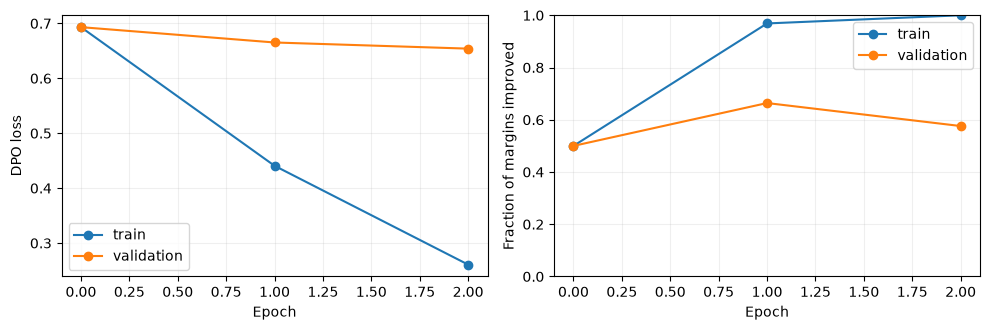

In [39]:
# To analyse the supplied run instead of your own, replace DPO_RESULTS_DIR below by Path('data/dpo/reference_135m').
dpo_config, dpo_metrics, dpo_answers = dpo.load_results(DPO_RESULTS_DIR)   # reads the saved tables; loads no model
# Table and plots of DPO loss and the fraction of margins improved, per epoch, for training and validation.
dpo.show_training(dpo_metrics)


**Q19 answer:** Interpret the training and validation curves, and explain what the final fraction of margins improved counts. If you analysed the supplied run rather than your own, say so (about four sentences).

Answer:
I analysed my own run (SmolLM2-135M-Instruct, 64 pairs, 2 epochs, beta 0.1). Training loss falls from 0.693 to 0.261 and the training fraction rises to 1.00, while validation loss falls only slightly (0.693 to 0.654) and the validation fraction peaks at 0.664 after epoch 1 and drops to 0.576 after epoch 2, so the model fits the 64 training pairs but generalises weakly and starts to overfit in the second epoch. The fraction of margins improved counts the pairs for which the policy's chosen-minus-rejected log-probability difference is larger than the reference model's (m_θ > 0), with exact ties counting half, which is why it is 0.5 at epoch 0 when policy and reference are identical. It measures only the direction of the change on these pairs, not how large it is and not whether generated answers are better.


### Q20. Examine the generated responses (1 mark)
**Interpretation TODO; generation code supplied.** Compare the saved answers before and after
fine-tuning. The same prompts and greedy decoding settings are used at each checkpoint. The output
also reports whether an answer hit the generation limit, which may affect the comparison.


In [40]:
# For each of the three prompts, prints the answer generated before training and after the final epoch,
# with its length in tokens and whether it hit the generation limit.
dpo.show_answers(dpo_answers)



PROMPT: Give me two ideas for using leftover cooked rice, carrots and peas.
Epoch 0 (128 tokens; hit generation limit: True):
Using leftover cooked rice, carrots, and peas can be a delightful and nutritious meal option. Here are two ideas:

1. **Grilled Chicken and Rice**:

Ingredients:
- 2 cups of leftover cooked rice
- 1 cup of carrots
- 1 cup of peas
- 1/2 cup of olive oil
- Salt and pepper to taste

Instructions:
1. Preheat your grill or broiler to medium-high heat.
2. Season the rice with salt and pepper.
3. Place the rice in the grill pan and cook for 2-3 minutes on each

Epoch 2 (128 tokens; hit generation limit: True):
Here are two ideas for using leftover cooked rice, carrots, and peas:

1. **Breakfast**:

* 1/2 cup of leftover cooked rice
* 1/2 cup of carrots
* 1/2 cup of peas
* 1/2 cup of cooked quinoa

This recipe is a great way to use leftover rice, carrots, and peas, and it's also a good source of protein and fiber.

2. **Lunch**:

* 1/2 cup of leftover cooked rice
* 1/2

**Q20 answer:** For one prompt, identify a specific improvement, regression or unchanged behaviour. Does this example support the conclusion that fine-tuning produced a better answer? Refer to the text (about three sentences).

Answer:
For the parcel prompt, before fine-tuning the model only says it cannot check the status of a specific item. After fine-tuning it says the same but adds "I recommend checking the official website or contacting the customer service of the company you ordered from", a concrete next step and both answers ended naturally (71 and 82 tokens, neither hit the generation limit). This is a small improvement in helpfulness, but it is one prompt with one greedy decoding run, so it does not show that fine-tuning produced better answers in general. The other two prompts do not support that conclusion: the fine-tuned rice answer added quinoa and an unsupported health claim and the fine-tuned airport answer invented an "IATA 123 route", while the validation margin fraction fell from 0.664 to 0.576 in the second epoch.


### Optional: Compare training configurations
**Unmarked activity; results supplied.** These completed staff experiments use a different 360M SFT
checkpoint. Compare 64 versus 1,024 training pairs (both beta 0.1), and beta 0.1 versus 0.5 with
1,024 pairs. All runs have five epochs; more pairs therefore also mean more updates.

The first plots recompute every loss at beta 0.1 for comparison. The second plots use each run's
own beta: compare training and validation within each panel. All training curves score the same
64-pair subset and validation curves use the same 125 pairs. Which checkpoint would you select using
the common validation loss? What does training longer change?

The printed parcel answers are from final checkpoints, not necessarily the checkpoint you select.
They use a 192-token limit, unlike the required run's 128. Compare answers within an experiment.
These supplied runs need not be repeated, and they do not isolate model size from training history.


In [41]:
RUN_OPTIONAL_DPO_COMPARISON = False
if RUN_OPTIONAL_DPO_COMPARISON:
    # Plots the three staff runs' losses (first at a common beta, then at each run's own beta), tabulates
    # the best and final validation loss per run, and prints each run's answer to the parcel prompt.
    dpo.staff_comparison()


## Before submission

**Deadline:** Sunday, 4 October 2026, 11:59 PM Indian Standard Time (IST).

**Submit at:** [Assignment submission form](https://docs.google.com/forms/d/e/1FAIpQLSfJTfSfDTtguBdAeX3STW_lUxZZF4WkimQL2oKiYvB-M0VEVw/viewform)

- Complete all required coding TODOs and Q3–Q5, Q7–Q9, Q10–Q16, Q19–Q20 written answers.
- Retain the outputs and plots. Include your pre-experiment prediction for Q13.
- Check that Q17 and Q18 sanity checks pass, and state your DPO result source in Q19.
- Rename the completed notebook `ROLLNUMBER_DA5453_Assignment2.ipynb`, replacing `ROLLNUMBER` with your own roll number.
- Submit only that `.ipynb` file. Do not submit model weights or the surrounding folder.
- Keep the emailed response receipt. To replace your notebook before the deadline, use **Edit your response** from that receipt and upload the revised file; do not create a second submission.
- Optional activities are not needed for full marks.
